# 3.0 — Segment map & stock

**Goal**: build the policy segmentation — `segmento` = `classe_social` × `status_empregaticio`
(binned cells from `bin_spec.yaml`, crossed per `references/segment_spec.yaml` by the new module
`credit_policy.segments`) — and map, per segment: population by `STATUS`, `score_klavi_2`
coverage, and the labeled book's default rate. Raw material for the per-segment score cutoffs
(notebooks 3.1/3.2).

**Input**: `data/interim/applications.parquet` (all STATUS, built in 1.1) + tuned
`bin_spec.yaml` (2.0) + `segment_spec.yaml`.
**Output**: `data/processed/applications_segmented.parquet` — the application table with the
merged `segmento` column (§4), consumed by 3.1+.

Sections 1–3 diagnose on the **raw product** (merges stripped) so every cell shows up;
§4 applies the merge decision persisted in the spec.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))
from credit_policy import binning, segments, woe, save_fig, palette  # noqa: E402  (path set above)

palette.apply_style()
pd.set_option("display.max_columns", 50)

APP_PATH = PROJECT_DIR / "data" / "interim" / "applications.parquet"
BIN_SPEC_PATH = PROJECT_DIR / "references" / "bin_spec.yaml"
SEG_SPEC_PATH = PROJECT_DIR / "references" / "segment_spec.yaml"
FIG_DIR = PROJECT_DIR / "reports" / "figures"  # deck figures land here

STATUS_ORDER = ["Contratado", "Aprovado", "Reprovado"]
C_STATUS = palette.FUNNEL  # blue ordinal STATUS ramp (Reprovado->Aprovado->Contratado)

app = pd.read_parquet(APP_PATH)
bin_spec = binning.load_spec(BIN_SPEC_PATH)
seg_spec = binning.load_spec(SEG_SPEC_PATH)

DIMS = seg_spec["segmento"]["dims"]
binned = binning.transform(app[DIMS], {d: bin_spec[d] for d in DIMS})
app["segmento"] = segments.apply_segment(binned, {"dims": DIMS})   # raw product for §§1–3
assert app["segmento"].notna().all()
print(f"{len(app):,} applications  |  cells: {list(app['segmento'].cat.categories)}")

220,618 applications  |  cells: ['A/B/C · Desconhecido', 'A/B/C · Autônomo', 'A/B/C · Formal', 'D/E · Desconhecido', 'D/E · Autônomo', 'D/E · Formal', '(missing)']


## 1. Population per segment — funnel × STATUS, score coverage

One row per product cell: STATUS counts, share of the funnel, approval rate under the current
policy (`Contratado`+`Aprovado`), and `score_klavi_2` coverage.

In [2]:
pop = (app.pivot_table(index="segmento", columns="STATUS", aggfunc="size",
                       fill_value=0, observed=False)[STATUS_ORDER])
pop["total"] = pop.sum(axis=1)
pop["pct_apps"] = (pop["total"] / pop["total"].sum() * 100).round(1)
pop["approval_pct"] = ((pop["Contratado"] + pop["Aprovado"]) / pop["total"] * 100).round(1)
pop["score_cov_pct"] = (app.groupby("segmento", observed=False)["score_klavi_2"]
                        .apply(lambda s: s.notna().mean() * 100).round(1))
pop

STATUS,Contratado,Aprovado,Reprovado,total,pct_apps,approval_pct,score_cov_pct
segmento,,,,,,,
A/B/C · Desconhecido,4318,13854,18114,36286,16.4,50.1,88.8
A/B/C · Autônomo,3404,11843,13416,28663,13.0,53.2,88.7
A/B/C · Formal,1810,5862,9871,17543,8.0,43.7,89.3
D/E · Desconhecido,2263,6556,15709,24528,11.1,36.0,90.0
D/E · Autônomo,501,1494,4071,6066,2.7,32.9,88.8
D/E · Formal,22,75,259,356,0.2,27.2,90.4
(missing),11830,37539,57807,107176,48.6,46.1,1.1


In [3]:
pop_risk = app.groupby("segmento").OVER30M2.mean().round(3)
pop_risk

segmento
A/B/C · Desconhecido    0.078
A/B/C · Autônomo        0.070
A/B/C · Formal          0.065
D/E · Desconhecido      0.155
D/E · Autônomo          0.164
D/E · Formal            0.136
(missing)               0.115
Name: OVER30M2, dtype: float64

**Key takeaway**: the `(missing)` segment is **48.6% of the funnel (107k) and 49% of the labeled
book**. Score coverage is
**~89–90% inside every named segment vs 1.1% in `(missing)`**: score and demographics are
co-missing, so a per-segment score cutoff is well-posed exactly on the named cells, and the
`(missing)` segment *is* the no-score path (its explicit rule is a 3.1 deliverable).

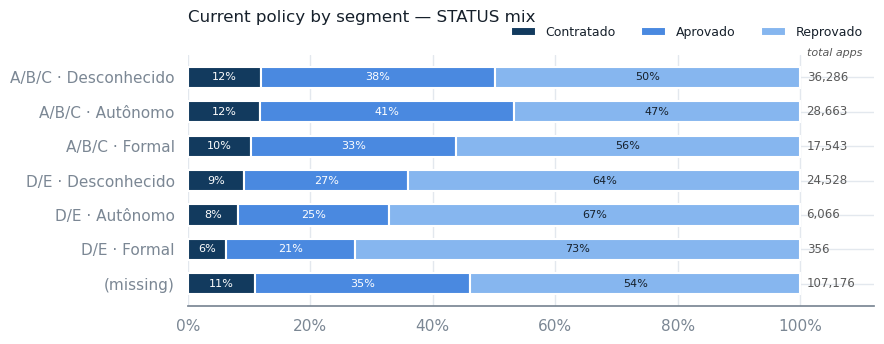

In [4]:
mix = pop[STATUS_ORDER].div(pop["total"], axis=0)
fig, ax = plt.subplots(figsize=(9, 3.6))
left = pd.Series(0.0, index=mix.index)
for st in STATUS_ORDER:
    ax.barh(mix.index.astype(str), mix[st], left=left, color=C_STATUS[st], label=st,
            edgecolor="white", linewidth=1.5, height=0.62)
    for i, cell in enumerate(mix.index):
        frac = mix.loc[cell, st]
        ax.text(left.iloc[i] + frac / 2, i, f"{frac:.0%}", va="center", ha="center",
                fontsize=8, color=palette.INK if st == "Reprovado" else "white")
    left = left + mix[st]
for i, cell in enumerate(mix.index):
    ax.text(1.01, i, f"{pop.loc[cell, 'total']:,}", va="center", fontsize=8.5, color="0.35")
ax.text(1.01, -0.62, "total apps", fontsize=8, color="0.35", style="italic")
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Current policy by segment — STATUS mix", loc="left", pad=24)
ax.legend(ncols=3, loc="lower right", bbox_to_anchor=(1.0, 1.02), frameon=False, fontsize=9)
sns.despine(left=True)
plt.tight_layout()
save_fig(fig, "fig_segment_map.png", FIG_DIR)
plt.show()

**Key takeaway**: the current policy already orders segments (approval 53.2% → 32.9% across
named cells) — but **not by risk**: `A/B/C · Formal` is the safest cell (6.5% default) yet gets
only 43.7% approval, below `A/B/C · Desconhecido` (50.1% approval at 7.8% default). Misordering
like this is exactly the swap-set opportunity the per-segment cutoffs target.

## 2. Swap-set map — measured risk vs unlabeled stock

Left: default rate in the book (measured; only `Contratado` has the target). Right: reachable
stock outside the book — `Aprovado` = demand that already passed the current policy,
`Reprovado` = the real expansion frontier, entirely unlabeled.

In [5]:
lab = app[app["OVER30M2"].notna()]
book = woe.woe_table(lab["segmento"], lab["OVER30M2"].astype(int))
book[["n", "bads", "goods", "bad_rate", "woe"]].round({"bad_rate": 4, "woe": 3})

,n,bads,goods,bad_rate,woe
bin,,,,,
A/B/C · Desconhecido,4318,336,3982,0.0778,0.307
A/B/C · Autônomo,3404,239,3165,0.0702,0.418
A/B/C · Formal,1810,118,1692,0.0652,0.495
D/E · Desconhecido,2263,351,1912,0.1551,-0.470
D/E · Autônomo,501,82,419,0.1637,-0.538
D/E · Formal,22,3,19,0.1364,-0.446
(missing),11830,1359,10471,0.1149,-0.122


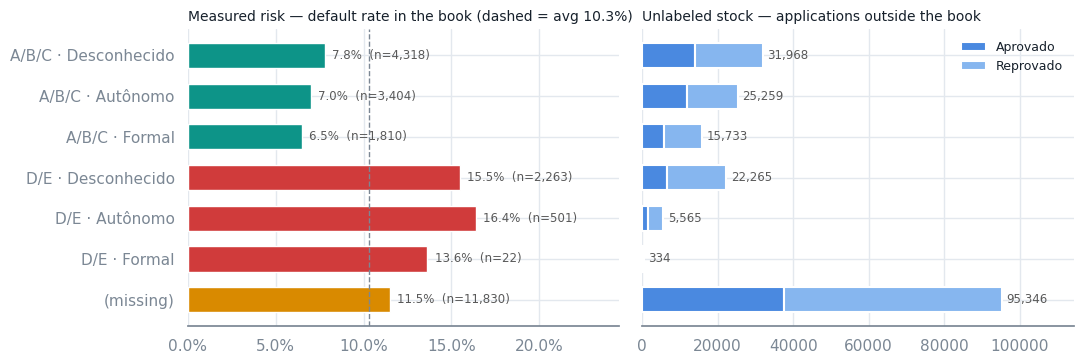

In [6]:
fig, (ax_r, ax_s) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
cells = book.index.astype(str)

base = lab["OVER30M2"].mean()
ax_r.barh(cells, book["bad_rate"],
          color=[palette.risk_tier_color(c) for c in book.index], height=0.62)
ax_r.axvline(base, color=palette.REF_LINE, ls="--", lw=1)
for i, (br, n) in enumerate(zip(book["bad_rate"], book["n"])):
    ax_r.text(br + 0.004, i, f"{br:.1%}  (n={n:,})", va="center", fontsize=8.5, color="0.35")
ax_r.invert_yaxis()
ax_r.set_xlim(0, book["bad_rate"].max() * 1.5)
ax_r.xaxis.set_major_formatter(PercentFormatter(1))
ax_r.set_title(f"Measured risk — default rate in the book (dashed = avg {base:.1%})",
               loc="left", fontsize=10)

left = pd.Series(0.0, index=pop.index)
for st in ["Aprovado", "Reprovado"]:
    ax_s.barh(cells, pop[st], left=left, color=C_STATUS[st], label=st,
              edgecolor="white", linewidth=1.5, height=0.62)
    left = left + pop[st]
for i, tot in enumerate(left):
    ax_s.text(tot + 1200, i, f"{int(tot):,}", va="center", fontsize=8.5, color="0.35")
ax_s.set_xlim(0, left.max() * 1.2)
ax_s.set_title("Unlabeled stock — applications outside the book", loc="left", fontsize=10)
ax_s.legend(loc="upper right", frameon=False, fontsize=9)
sns.despine(left=True)
plt.tight_layout()
save_fig(fig, "fig_segment_risk_tiers.png", FIG_DIR)
plt.show()

**Key takeaway**: risk splits into three tiers — **A/B/C 6.5–7.8%, `(missing)` 11.5%, D/E
15.5–16.4%** (a 2.4× spread; WoE +0.50 → −0.54). The reachable stock concentrates where risk is
lowest: A/B/C holds 31.6k `Aprovado` + 41.4k `Reprovado`, and `(missing)` another 95.3k.
`D/E · Formal` has **22 labeled rows** — unusable as its own cutoff cell.

## 3. Thin cells — merge decision (persisted in `segment_spec.yaml`)

`D/E · Formal` (22 labeled / 356 total) cannot support its own cutoff, and its bad rate (13.6%)
is statistically indistinguishable from `D/E · Autônomo` (16.4%). **Decision: merge into
`D/E · Autônomo/Formal`**, recorded as `groups:` in `segment_spec.yaml` — the same hand-merge
mechanism as `bin_spec.yaml`. From here on (3.1+), `segmento` means the persisted spec's version.

In [7]:
app["segmento"] = segments.make_segments(binned, seg_spec)["segmento"]   # persisted spec
lab = app[app["OVER30M2"].notna()]
woe.woe_table(lab["segmento"], lab["OVER30M2"].astype(int))[
    ["n", "bads", "goods", "bad_rate", "woe"]].round({"bad_rate": 4, "woe": 3})

,n,bads,goods,bad_rate,woe
bin,,,,,
A/B/C · Desconhecido,4318,336,3982,0.0778,0.307
A/B/C · Autônomo,3404,239,3165,0.0702,0.418
A/B/C · Formal,1810,118,1692,0.0652,0.495
D/E · Desconhecido,2263,351,1912,0.1551,-0.470
D/E · Autônomo/Formal,523,85,438,0.1625,-0.529
(missing),11830,1359,10471,0.1149,-0.122


## 4. Persist — `data/processed/applications_segmented.parquet`

The merged segmentation is this notebook's decision, so it leaves as an artifact: the interim
application table plus the `segmento` column. Notebooks 3.1+ consume this table instead of
re-deriving the segmentation.

In [8]:
OUT_PATH = PROJECT_DIR / "data" / "processed" / "applications_segmented.parquet"
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
assert len(app) == 220_618 and app["segmento"].notna().all() and app["segmento"].cat.ordered
app.to_parquet(OUT_PATH)

check = pd.read_parquet(OUT_PATH)["segmento"]   # round-trip keeps the ordered categorical
assert check.cat.ordered and list(check.cat.categories) == list(app["segmento"].cat.categories)
print(f"written {OUT_PATH.relative_to(PROJECT_DIR)}  |  {len(app):,} rows  |  "
      f"cells: {list(check.cat.categories)}")

written data/processed/applications_segmented.parquet  |  220,618 rows  |  cells: ['A/B/C · Desconhecido', 'A/B/C · Autônomo', 'A/B/C · Formal', 'D/E · Desconhecido', 'D/E · Autônomo/Formal', '(missing)']


## Key takeaways

- **Segmentation built and persisted**: 5 named cells + `(missing)`, declared in
  `segment_spec.yaml`, crossed by `credit_policy.segments`, and written to
  `data/processed/applications_segmented.parquet` — 3.1+ consume the column; the WoE/PSI
  machinery applies to it unchanged.
- **`(missing)` is half of everything** (48.6% of funnel, 49% of book, 11.5% default) and holds
  almost no score (1.1%) — it is the no-score path and needs its own explicit rule, not a cutoff.
- **Named cells order cleanly by risk** (6.5% → 16.4%, 2.4×) and carry ~89–90% score coverage —
  the per-segment `score_klavi_2` cutoff is well-posed exactly where it applies.
- **The current policy misorders at least one cell**: `A/B/C · Formal`, the safest, is approved
  *less* than riskier A/B/C cells — direct swap-set evidence for 3.2.
- **Stock skews safe**: 73k unlabeled applications sit in A/B/C cells (37% of the non-book) —
  but only `Aprovado` (31.6k) passed the current policy; opening to `Reprovado` (41.4k) rests on
  the unverifiable-extrapolation caveat.
- **Next (3.1)**: per-segment baseline WoE / stability, `score_klavi_2` WoE within each named
  segment (monotonicity), and the explicit `(missing)`-path rule.